In [2]:
import pandas as pd
import numpy as np

genetics_test = pd.read_csv("data/test.csv")
genetics_train = pd.read_csv("data/train.csv")

genetics = pd.concat([genetics_test, genetics_train], ignore_index = True) #ignore_index = True, to get new indexes from 0 to 31547
genetics.replace({False: 0, True: 1}, inplace=True)

display(genetics)
#Remove: Patient first name, family name, Father's name, Insitute name, Institute location, Parental consent, 

C:\Users\malin\AppData\Local\Temp\ipykernel_25584\50206612.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  genetics.replace({False: 0, True: 1}, inplace=True)


,Patient Id,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Patient First Name,Family Name,Father's name,...,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5,Genetic Disorder,Disorder Subclass
0,PID0x4175,6.0,No,Yes,No,No,4.981655,Charles,NaN,Kore,...,Multiple,-99.000000,slightly abnormal,1.0,1.0,1.0,1.0,1.0,NaN,NaN
1,PID0x21f5,10.0,Yes,No,NaN,Yes,5.118890,Catherine,NaN,Homero,...,Multiple,8.179584,normal,0.0,0.0,0.0,1.0,0.0,NaN,NaN
2,PID0x49b8,5.0,No,NaN,No,No,4.876204,James,NaN,Danield,...,Singular,-99.000000,slightly abnormal,0.0,0.0,1.0,1.0,0.0,NaN,NaN
3,PID0x2d97,13.0,No,Yes,Yes,No,4.687767,Brian,NaN,Orville,...,Singular,6.884071,normal,1.0,0.0,1.0,0.0,1.0,NaN,NaN
4,PID0x58da,5.0,No,NaN,NaN,Yes,5.152362,Gary,NaN,Issiah,...,Multiple,6.195178,normal,1.0,1.0,1.0,1.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31543,PID0x5598,4.0,Yes,Yes,Yes,No,5.258298,Lynn,NaN,Alhassane,...,Multiple,6.584811,inconclusive,0.0,0.0,1.0,0.0,0.0,Mitochondrial genetic inheritance disorders,Leigh syndrome
31544,PID0x19cb,8.0,No,Yes,No,Yes,4.974220,Matthew,Farley,Dartanion,...,Multiple,7.041556,inconclusive,1.0,1.0,1.0,1.0,0.0,Multifactorial genetic inheritance disorders,Diabetes
31545,PID0x3c4f,8.0,Yes,No,Yes,No,5.186470,John,NaN,Cavani,...,Singular,7.715464,normal,0.0,0.0,0.0,1.0,NaN,Mitochondrial genetic inheritance disorders,Mitochondrial myopathy
31546,PID0x13a,7.0,Yes,No,Yes,Yes,4.858543,Sharon,NaN,Bomer,...,Multiple,8.437670,abnormal,1.0,1.0,1.0,0.0,0.0,NaN,Leigh syndrome


In [146]:
target_column1 = "Genetic Disorder"
#target1 = genetics[target_column1]
genetics[target_column1].value_counts()

Genetic Disorder
Mitochondrial genetic inheritance disorders     10202
Single-gene inheritance diseases                 7664
Multifactorial genetic inheritance disorders     2071
Name: count, dtype: int64

In [147]:
target_column2 = "Disorder Subclass"
#target2 = genetics[target_column2]
genetics[target_column2].value_counts()

Disorder Subclass
Leigh syndrome                         5160
Mitochondrial myopathy                 4405
Cystic fibrosis                        3448
Tay-Sachs                              2833
Diabetes                               1817
Hemochromatosis                        1355
Leber's hereditary optic neuropathy     648
Alzheimer's                             152
Cancer                                   97
Name: count, dtype: int64

In [148]:
#genetics["Patient Id"].value_counts()
genetics["Test 1"].value_counts()
genetics["Test 2"].value_counts()

Test 2
 0.0     27315
-99.0     2081
Name: count, dtype: int64

In [149]:
genetics.columns.values.tolist()
#print(genetics['Respiratory Rate (breaths/min)'])
#genetics['Respiratory Rate (breaths/min)'].value_counts()

['Patient Id',
 'Patient Age',
 "Genes in mother's side",
 'Inherited from father',
 'Maternal gene',
 'Paternal gene',
 'Blood cell count (mcL)',
 'Patient First Name',
 'Family Name',
 "Father's name",
 "Mother's age",
 "Father's age",
 'Institute Name',
 'Location of Institute',
 'Status',
 'Respiratory Rate (breaths/min)',
 'Heart Rate (rates/min',
 'Test 1',
 'Test 2',
 'Test 3',
 'Test 4',
 'Test 5',
 'Parental consent',
 'Follow-up',
 'Gender',
 'Birth asphyxia',
 'Autopsy shows birth defect (if applicable)',
 'Place of birth',
 'Folic acid details (peri-conceptional)',
 'H/O serious maternal illness',
 'H/O radiation exposure (x-ray)',
 'H/O substance abuse',
 'Assisted conception IVF/ART',
 'History of anomalies in previous pregnancies',
 'No. of previous abortion',
 'Birth defects',
 'White Blood cell count (thousand per microliter)',
 'Blood test result',
 'Symptom 1',
 'Symptom 2',
 'Symptom 3',
 'Symptom 4',
 'Symptom 5',
 'Genetic Disorder',
 'Disorder Subclass']

array([[<Axes: title={'center': 'Patient Age'}>,
        <Axes: title={'center': 'Blood cell count (mcL)'}>,
        <Axes: title={'center': "Mother's age"}>],
       [<Axes: title={'center': "Father's age"}>,
        <Axes: title={'center': 'Test 1'}>,
        <Axes: title={'center': 'Test 2'}>],
       [<Axes: title={'center': 'Test 3'}>,
        <Axes: title={'center': 'Test 4'}>,
        <Axes: title={'center': 'Test 5'}>],
       [<Axes: title={'center': 'No. of previous abortion'}>,
        <Axes: title={'center': 'White Blood cell count (thousand per microliter)'}>,
        <Axes: >]], dtype=object)

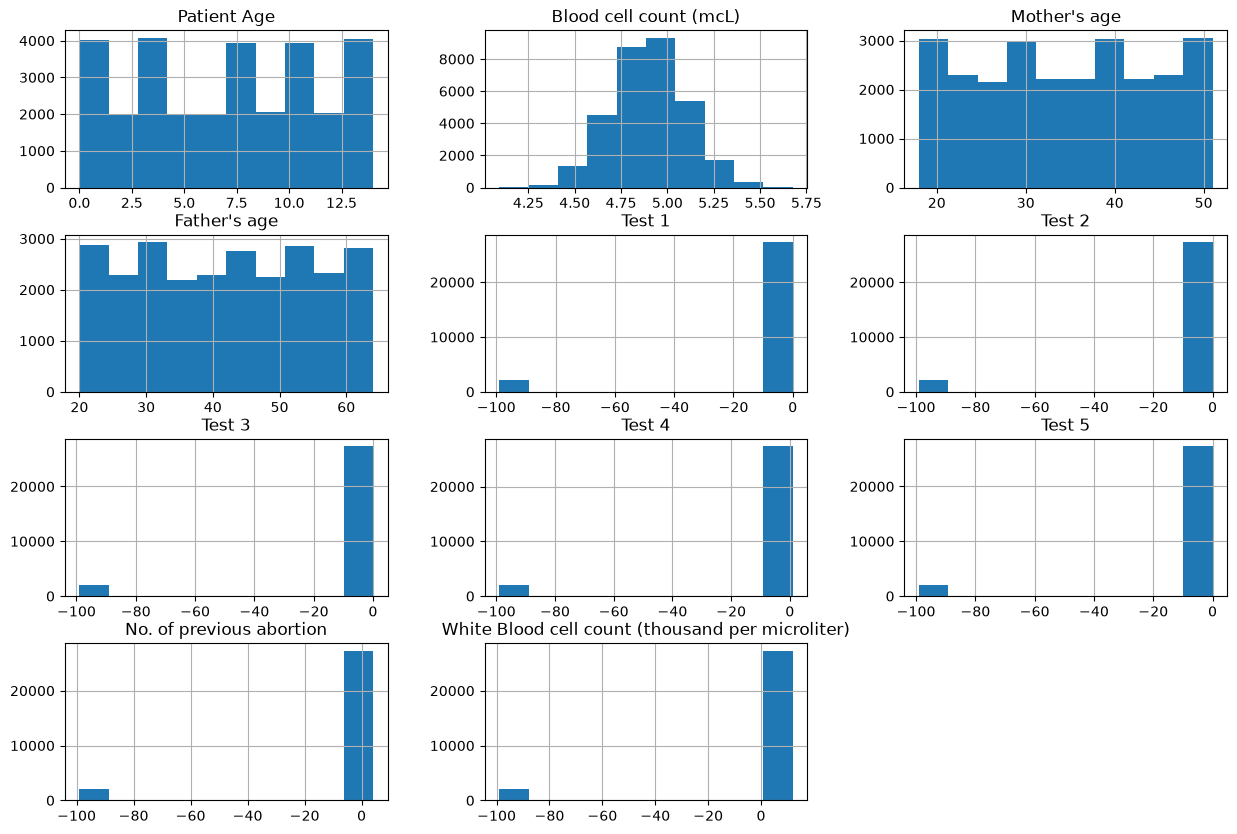

In [150]:
genetics.hist(figsize = (15,10))

Patient Age                                         float64
Genes in mother's side                                  str
Inherited from father                                   str
Maternal gene                                           str
Paternal gene                                           str
Blood cell count (mcL)                              float64
Mother's age                                        float64
Father's age                                        float64
Status                                                  str
Respiratory Rate (breaths/min)                          str
Heart Rate (rates/min                                   str
Test 1                                              float64
Test 2                                              float64
Test 3                                              float64
Test 4                                              float64
Test 5                                              float64
Follow-up                               

,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Mother's age,Father's age,Status,Respiratory Rate (breaths/min),...,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5,Genetic Disorder,Disorder Subclass
0,6.0,No,Yes,No,No,4.981655,38.0,61.0,Alive,Tachypnea,...,Multiple,NaN,slightly abnormal,1.0,1.0,1.0,1.0,1.0,NaN,NaN
1,10.0,Yes,No,NaN,Yes,5.118890,33.0,53.0,Alive,NaN,...,Multiple,8.179584,normal,0.0,0.0,0.0,1.0,0.0,NaN,NaN
2,5.0,No,NaN,No,No,4.876204,48.0,60.0,Deceased,NaN,...,Singular,NaN,slightly abnormal,0.0,0.0,1.0,1.0,0.0,NaN,NaN
3,13.0,No,Yes,Yes,No,4.687767,25.0,55.0,Alive,NaN,...,Singular,6.884071,normal,1.0,0.0,1.0,0.0,1.0,NaN,NaN
4,5.0,No,NaN,NaN,Yes,5.152362,41.0,38.0,Deceased,Tachypnea,...,Multiple,6.195178,normal,1.0,1.0,1.0,1.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31543,4.0,Yes,Yes,Yes,No,5.258298,35.0,64.0,Deceased,Normal (30-60),...,Multiple,6.584811,inconclusive,0.0,0.0,1.0,0.0,0.0,Mitochondrial genetic inheritance disorders,Leigh syndrome
31544,8.0,No,Yes,No,Yes,4.974220,NaN,56.0,Alive,Normal (30-60),...,Multiple,7.041556,inconclusive,1.0,1.0,1.0,1.0,0.0,Multifactorial genetic inheritance disorders,Diabetes
31545,8.0,Yes,No,Yes,No,5.186470,35.0,51.0,Deceased,Tachypnea,...,Singular,7.715464,normal,0.0,0.0,0.0,1.0,NaN,Mitochondrial genetic inheritance disorders,Mitochondrial myopathy
31546,7.0,Yes,No,Yes,Yes,4.858543,19.0,NaN,Alive,Tachypnea,...,Multiple,8.437670,abnormal,1.0,1.0,1.0,0.0,0.0,NaN,Leigh syndrome


Patient Age                                         float64
Genes in mother's side                                  str
Inherited from father                                   str
Maternal gene                                           str
Paternal gene                                           str
Blood cell count (mcL)                              float64
Mother's age                                        float64
Father's age                                        float64
Status                                                  str
Respiratory Rate (breaths/min)                          str
Heart Rate (rates/min                                   str
Test 1                                              float64
Test 2                                              float64
Test 3                                              float64
Test 4                                              float64
Test 5                                              float64
Follow-up                               

array([[<Axes: title={'center': 'Patient Age'}>,
        <Axes: title={'center': 'Blood cell count (mcL)'}>,
        <Axes: title={'center': "Mother's age"}>,
        <Axes: title={'center': "Father's age"}>],
       [<Axes: title={'center': 'Test 1'}>,
        <Axes: title={'center': 'Test 2'}>,
        <Axes: title={'center': 'Test 3'}>,
        <Axes: title={'center': 'Test 4'}>],
       [<Axes: title={'center': 'Test 5'}>,
        <Axes: title={'center': 'No. of previous abortion'}>,
        <Axes: title={'center': 'White Blood cell count (thousand per microliter)'}>,
        <Axes: title={'center': 'Symptom 1'}>],
       [<Axes: title={'center': 'Symptom 2'}>,
        <Axes: title={'center': 'Symptom 3'}>,
        <Axes: title={'center': 'Symptom 4'}>,
        <Axes: title={'center': 'Symptom 5'}>]], dtype=object)

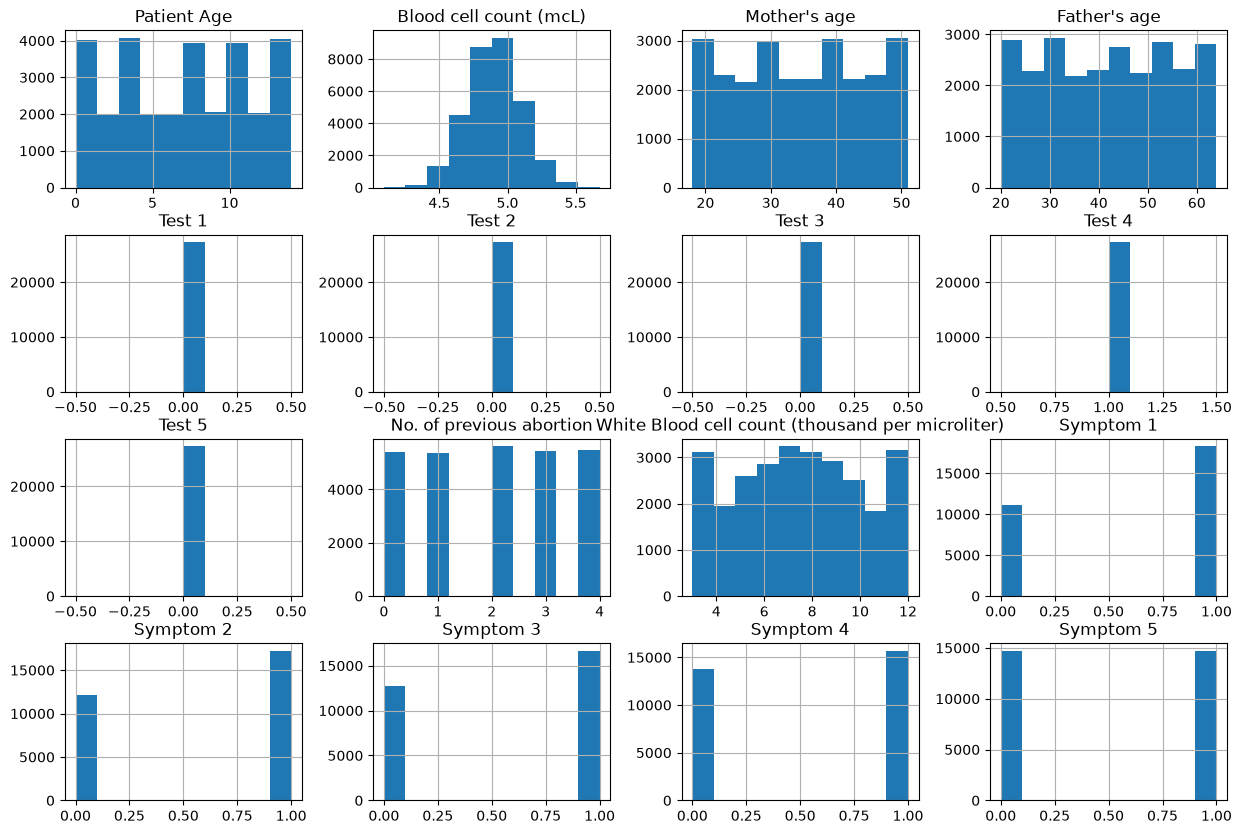

In [151]:
#Drop irelevant columns
data = genetics.drop(columns=["Patient Id", "Patient First Name", "Family Name", "Father's name", "Institute Name", "Location of Institute", "Parental consent", "Place of birth"])

#Change -99 to NaN
cols = data.select_dtypes(np.number).columns
data[cols] = data[cols].mask(np.isclose(data[cols].values, -99))
data = data.replace('-99', np.nan)

#Change type from object to float
data[["Symptom 1", "Symptom 2", "Symptom 3", "Symptom 4", "Symptom 5"]] = data[["Symptom 1", "Symptom 2", "Symptom 3", "Symptom 4", "Symptom 5"]].astype(float)
print(data.dtypes)

display(data)
print(data.dtypes)

data.hist(figsize = (15,10))


In [152]:
data['Respiratory Rate (breaths/min)'].value_counts() #Test
data['Heart Rate (rates/min'].value_counts()

Heart Rate (rates/min
Normal         12408
Tachycardia    12053
Name: count, dtype: int64

Dummy

In [153]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split

dataDummy = data.drop(columns=[target_column1, target_column2])

target1Dummy = data[target_column1]

# Remove rows with missing target values
valid_rows = target1Dummy.notna()
dataDummy = dataDummy.loc[valid_rows]
target1Dummy = target1Dummy.loc[valid_rows]

# Train/test split
data_trainDummy, data_testDummy, target1_trainDummy, target1_testDummy = train_test_split(dataDummy, target1Dummy, random_state=42,test_size=0.25)

Dummy = DummyClassifier(strategy="most_frequent")
Dummy.fit(data_trainDummy, target1_trainDummy)

accuracy = Dummy.score(data_testDummy, target1_testDummy)

print(f"Accuracy of DummyClassifier: {accuracy:.3f}")

Accuracy of DummyClassifier: 0.509


K-nearest neighbor

In [154]:
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_selector as selector

data_non_nan = data.dropna(axis=0, how='any')
dataK = data_non_nan.drop(columns = [target_column1, target_column2])

numerical_columns_selector = selector(dtype_exclude=["object", "string"])
numerical_columns = numerical_columns_selector(dataK)
numerical_dataK = dataK[numerical_columns]
target1K = data_non_nan[target_column1]
target2K = data_non_nan[target_column2]
                  
data_trainK, data_testK, target1_trainK, target1_testK = train_test_split(numerical_dataK, target1K, random_state=42, test_size=0.25)

from sklearn.neighbors import KNeighborsClassifier
Kneighbor = KNeighborsClassifier()
_ = Kneighbor.fit(data_trainK, target1_trainK)

accuracy = Kneighbor.score(data_testK, target1_testK)
model_name = Kneighbor.__class__.__name__
print(f"The test accuracy using a {model_name} is {accuracy:.3f}")

The test accuracy using a KNeighborsClassifier is 0.483


Logistic Regression

In [155]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import make_column_selector as selector
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

data_non_nan = data.dropna(axis=0, how='any')
dataLogistic = data_non_nan.drop(columns = [target_column1, target_column2])

categorical_preprocessor = OneHotEncoder(handle_unknown="ignore")
numerical_preprocessor = StandardScaler()

numerical_columns_selector = selector(dtype_exclude=["object", "string"])
categorical_columns_selector = selector(dtype_include=["object", "string"])
numerical_columns = numerical_columns_selector(dataLogistic)
categorical_columns = categorical_columns_selector(dataLogistic)
target1Logistic = data_non_nan[target_column1]
target2Logistic = data_non_nan[target_column2]

from sklearn.compose import make_column_transformer
preprocessor = make_column_transformer((categorical_preprocessor, categorical_columns), (numerical_preprocessor, numerical_columns))

data_trainLogistic, data_testLogistic, target1_trainLogistic, target1_testLogistic = train_test_split(dataLogistic, target1Logistic, random_state=42, test_size=0.25)

Logistic_reg = make_pipeline(preprocessor, LogisticRegression(max_iter=500))
Logistic_reg.fit(data_trainLogistic, target1_trainLogistic)
#predicted_target = model.predict(data_test)

accuracy = Logistic_reg.score(data_testLogistic, target1_testLogistic)
print(f"Accuracy of logistic regression: {accuracy:.3f}")

Accuracy of logistic regression: 0.537


HistGradientBoosting

In [156]:
"""
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import make_column_selector as selector
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline

#data_non_nan = data.dropna(axis=0, how='any')
dataHist = data.drop(columns = [target_column1, target_column2])

categorical_preprocessor = OrdinalEncoder( handle_unknown="use_encoded_value",unknown_value=-1,encoded_missing_value=-2)

numerical_columns_selector = selector(dtype_exclude=["object", "string"])
categorical_columns_selector = selector(dtype_include=["object", "string"])
numerical_columns = numerical_columns_selector(dataHist)
categorical_columns = categorical_columns_selector(dataHist)
target1Hist = data[target_column1]
target2Hist = data[target_column2]

print(dataHist.isna().sum())
print(target1Hist.isna().sum())

print(dataHist.isna().sum().sum())

from sklearn.compose import make_column_transformer
preprocessor = make_column_transformer((categorical_preprocessor, categorical_columns),remainder="passthrough",)

data_trainHist, data_testHist, target1_trainHist, target1_testHist = train_test_split(dataHist, target1Hist, random_state=42, test_size=0.25)

Histgrad = make_pipeline(preprocessor, HistGradientBoostingClassifier())
Histgrad.fit(data_trainHist, target1_trainHist)
#predicted_target = model.predict(data_test)

accuracy = Logistic_reg.score(data_testHist, target1_testHist)
print(f"Accuracy of logistic regression: {accuracy:.3f}")
"""

'\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.preprocessing import OrdinalEncoder\nfrom sklearn.compose import make_column_selector as selector\nfrom sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier\nfrom sklearn.pipeline import make_pipeline\n\n#data_non_nan = data.dropna(axis=0, how=\'any\')\ndataHist = data.drop(columns = [target_column1, target_column2])\n\ncategorical_preprocessor = OrdinalEncoder( handle_unknown="use_encoded_value",unknown_value=-1,encoded_missing_value=-2)\n\nnumerical_columns_selector = selector(dtype_exclude=["object", "string"])\ncategorical_columns_selector = selector(dtype_include=["object", "string"])\nnumerical_columns = numerical_columns_selector(dataHist)\ncategorical_columns = categorical_columns_selector(dataHist)\ntarget1Hist = data[target_column1]\ntarget2Hist = data[target_column2]\n\nprint(dataHist.isna().sum())\nprint(target1Hist.isna().sum())\n\nprint(dataHist.isna().sum().sum())\n\nfrom skle

In [157]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import make_column_selector as selector
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
dataHist = data.drop(columns=[target_column1, target_column2])

target1Hist = data[target_column1]

# Remove rows with missing target values
# Can handle NaN in X, but not in y
valid_rows = target1Hist.notna()
dataHist = dataHist.loc[valid_rows]
target1Hist = target1Hist.loc[valid_rows]

# Preprocessing
categorical_preprocessor = OrdinalEncoder(handle_unknown="use_encoded_value",unknown_value=-1,encoded_missing_value=-2)

numerical_columns_selector = selector(dtype_exclude=["object", "string"])
categorical_columns_selector = selector(dtype_include=["object", "string"])

numerical_columns = numerical_columns_selector(dataHist)
categorical_columns = categorical_columns_selector(dataHist)

preprocessor = make_column_transformer((categorical_preprocessor, categorical_columns),remainder="passthrough")

# Train/test split
data_trainHist, data_testHist, target1_trainHist, target1_testHist = train_test_split(dataHist, target1Hist, random_state=42, test_size=0.25)

# Model
Histgrad = make_pipeline(preprocessor,HistGradientBoostingClassifier())

Histgrad.fit(data_trainHist, target1_trainHist)

# Predictions and accuracy
predicted_target = Histgrad.predict(data_testHist)

accuracy = Histgrad.score(data_testHist, target1_testHist)

print(f"Accuracy of HistGradientBoostingClassifier: {accuracy:.3f}")

Accuracy of HistGradientBoostingClassifier: 0.594
